# Práctica 6: Neurona completa (peso y sesgo) con NumPy

## Objetivo
En este último cuaderno se retoma el modelo completo $y = wx + b$[cite: 65, 66]. A diferencia de las versiones anteriores, implementaremos el ajuste simultáneo del peso y el sesgo utilizando arreglos de NumPy para vectorizar las operaciones[cite: 66]. Además, se representarán gráficamente el costo, la evolución del peso y del sesgo, y el modelo obtenido después del entrenamiento comparado con los datos reales[cite: 66].

## Datos de Entrenamiento
Se utilizan los siguientes arreglos numéricos:
* Entradas ($x$): `np.array([1, 2, 3, 4])`[cite: 66]
* Salidas esperadas ($t$): `np.array([4, 6, 8, 10])`[cite: 66]

Sabemos de antemano que la relación esperada es $t = 2x + 2$.

## Modelo Matemático y Gradientes Simultáneos

El modelo predictivo lineal completo incorpora ahora el parámetro del sesgo ($b$):
$$y = wx + b$$

### Función de Costo (Vectorizada)
Al utilizar NumPy, el error cuadrático individual se calcula para todo el arreglo simultáneamente mediante $E = (y - t)^2$[cite: 66]. Posteriormente se utiliza `np.mean()` para obtener la función de costo global o error cuadrático medio ($J$).

### Descenso por Gradiente y Regla de la Cadena
Para ajustar ambos parámetros, debemos calcular la derivada del error respecto a cada uno aplicando la regla de la cadena.

**1. Derivada respecto a la salida:**
$$\frac{\partial E}{\partial y} = 2(y - t)$$

**2. Derivadas respecto al peso ($w$):**
Sabiendo que $\frac{\partial y}{\partial w} = x$[cite: 32], al aplicar la regla de la cadena obtenemos[cite: 32]:
$$\frac{\partial E}{\partial w} = \frac{\partial E}{\partial y} \cdot \frac{\partial y}{\partial w} = 2(y - t)x$$

**3. Derivadas respecto al sesgo ($b$):**
Dado que $\frac{\partial y}{\partial b} = 1$[cite: 32], la regla de la cadena nos indica que[cite: 32]:
$$\frac{\partial E}{\partial b} = \frac{\partial E}{\partial y} \cdot \frac{\partial y}{\partial b} = 2(y - t)$$

### Actualización Simultánea
Mediante `np.mean()`, calculamos los gradientes promedio globales $\frac{\partial J}{\partial w}$ y $\frac{\partial J}{\partial b}$[cite: 67]. Ambos parámetros se actualizan simultáneamente restando sus respectivos gradientes multiplicados por la tasa de aprendizaje ($\eta = 0.1$)[cite: 67, 68]:
$$w_{nuevo} = w_{anterior} - \eta \frac{\partial J}{\partial w}$$
$$b_{nuevo} = b_{anterior} - \eta \frac{\partial J}{\partial b}$$


EPOCA 1
Entrada:  1.0 |Target:   4.0 | Pred:   0.4000 | Error^2:  12.9600 |dE/dw:   -7.2000 |dE/db:   -7.2000
Entrada:  2.0 |Target:   6.0 | Pred:   0.5000 | Error^2:  30.2500 |dE/dw:  -22.0000 |dE/db:  -11.0000
Entrada:  3.0 |Target:   8.0 | Pred:   0.6000 | Error^2:  54.7600 |dE/dw:  -44.4000 |dE/db:  -14.8000
Entrada:  4.0 |Target:  10.0 | Pred:   0.7000 | Error^2:  86.4900 |dE/dw:  -74.4000 |dE/db:  -18.6000
Costo promedio: 46.115000
Gradiente dJ/dw: -37.000000
Gradiente dJ/db: -12.900000
Peso antes: 0.100000
Bias antes: 0.300000
Peso despues: 3.800000
Bias despues: 1.590000

EPOCA 2
Entrada:  1.0 |Target:   4.0 | Pred:   5.3900 | Error^2:   1.9321 |dE/dw:    2.7800 |dE/db:    2.7800
Entrada:  2.0 |Target:   6.0 | Pred:   9.1900 | Error^2:  10.1761 |dE/dw:   12.7600 |dE/db:    6.3800
Entrada:  3.0 |Target:   8.0 | Pred:  12.9900 | Error^2:  24.9001 |dE/dw:   29.9400 |dE/db:    9.9800
Entrada:  4.0 |Target:  10.0 | Pred:  16.7900 | Error^2:  46.1041 |dE/dw:   54.3200 |dE/db:   13.5

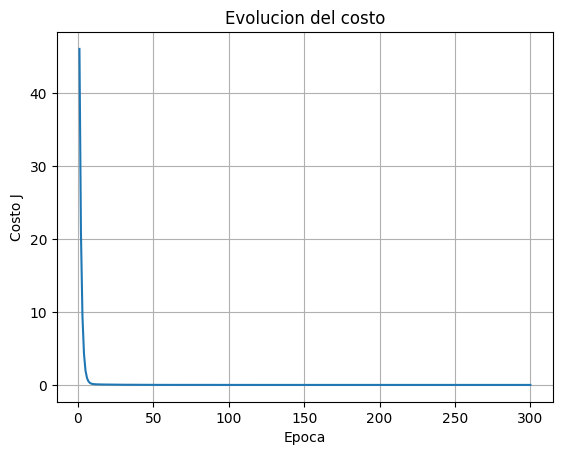

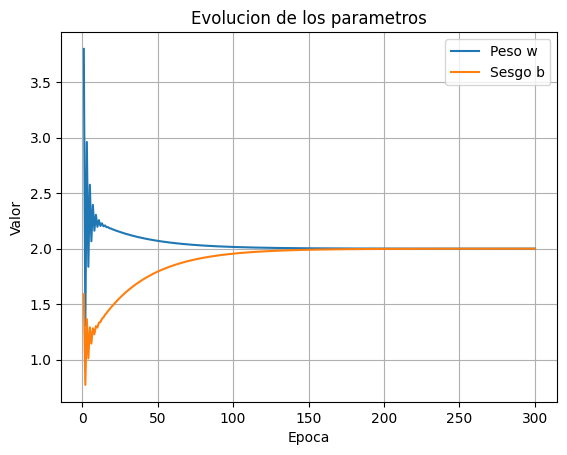

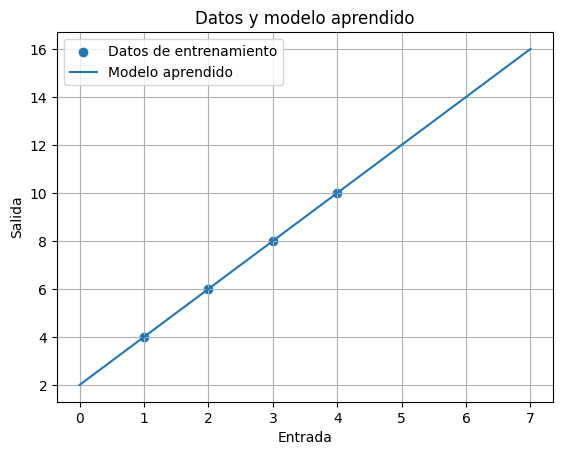

In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt

inputs = np.array([1, 2, 3, 4], dtype=float)
targets = np.array([4, 6, 8, 10], dtype=float)

w = 0.1
b = 0.3

epochs = 300
learning_rate = 0.1
pause_time = 0.1

weight_history = []
bias_history = []
cost_history = []

for epoch in range(epochs):
    predictions = (w * inputs + b)
    
    errors = (predictions - targets)**2
    
    cost = np.mean(errors)
    
    errors_d = (2 * (predictions - targets))
    
    weight_d = (errors_d * inputs)
    
    bias_d = errors_d
    
    gradient_w = np.mean(weight_d)
    
    gradient_b = np.mean(bias_d)
    
    print("\n" + "=" * 70)
    print(f"EPOCA {epoch + 1}")
    print("=" * 70)
    
    for i, t, p, e, wd, bd in zip(inputs, targets, predictions, errors, weight_d, bias_d):
        print(
            f"Entrada: {i:>4.1f} |"
            f"Target: {t:>5.1f} | "
            f"Pred: {p:>8.4f} | "
            f"Error^2: {e:>8.4f} |"
            f"dE/dw: {wd:>9.4f} |"
            f"dE/db: {bd:>9.4f}"
        )
        
    print(f"Costo promedio: {cost:.6f}")
    print(f"Gradiente dJ/dw: {gradient_w:.6f}")
    print(f"Gradiente dJ/db: {gradient_b:.6f}")
    print(f"Peso antes: {w:.6f}")
    print(f"Bias antes: {b:.6f}")
    
    w -= (learning_rate * gradient_w)
    
    b -= (learning_rate * gradient_b)
    
    print(f"Peso despues: {w:.6f}")
    print(f"Bias despues: {b:.6f}")
    
    weight_history.append(w)
    bias_history.append(b)
    cost_history.append(cost)
    
    time.sleep(pause_time)

test_inputs = np.array([5, 6], dtype=float)
test_predictions = (w * test_inputs + b)

print("\n" + "=" * 70)
print("PRUEBA FINAL")
print("=" * 70)

for i, p in zip(test_inputs, test_predictions):
    print(
        f"Entrada: {i:>4.1f} | "
        f"Prediccion: {p:>8.4f}"
    )

plt.figure()
plt.plot(range(1, epochs + 1), cost_history)
plt.xlabel("Epoca")
plt.ylabel("Costo J")
plt.title("Evolucion del costo")
plt.grid()
plt.show()

plt.figure()
plt.plot(range(1, epochs + 1), weight_history, label="Peso w")
plt.plot(range(1, epochs + 1), bias_history, label="Sesgo b")
plt.xlabel("Epoca")
plt.ylabel("Valor")
plt.title("Evolucion de los parametros")
plt.legend()
plt.grid()
plt.show()

x_plot = np.linspace(0, 7, 100)
y_plot = (w * x_plot + b)

plt.figure()
plt.scatter(inputs, targets, label="Datos de entrenamiento")
plt.plot(x_plot, y_plot, label="Modelo aprendido")
plt.xlabel("Entrada")
plt.ylabel("Salida")
plt.title("Datos y modelo aprendido")
plt.legend()
plt.grid()
plt.show()

## Análisis de Resultados y Reporte Gráfico

Al finalizar el entrenamiento de 300 épocas, el modelo arroja conclusiones visuales muy sólidas:
1. **Caída del Costo:** Como se observa en la evolución del costo, el error promedio cae rápidamente a valores sumamente pequeños y cercanos a cero[cite: 71]. Debido a que alcanza valores tan pequeños, su comportamiento real es de decaimiento exponencial[cite: 71].
2. **Convergencia Paramétrica:** La gráfica de evolución simultánea muestra cómo ambos parámetros inician en valores arbitrarios ($w=0.1$ y $b=0.3$) e iterativamente convergen hacia los valores óptimos ($w \approx 2$ y $b \approx 2$)[cite: 70, 72]. 
3. **Mapeo del Modelo Aprendido:** La última gráfica superpone el modelo final ($y = 2x + 2$) sobre los datos originales[cite: 70, 72]. Se evidencia gráficamente el éxito absoluto del aprendizaje, ya que la recta aprendida pasa prácticamente por los cuatro puntos de entrenamiento exactos[cite: 72].